# Step 3a: LambdaRank learning-to-rank model

**Goal:** rerank each search's candidate list so clicked, carted and purchased products rise to the top. We train a LightGBM LambdaRank model on graded labels (0 none, 1 click, 2 cart, 3 purchase) using:

- Step 1a: user history features (per search), exact-product history and brand/shop/category history (per search × product)
- Step 1b: 7 product attributes and 4 query-product matching features, including BM25
- Step 2: 13 popularity features from train users' past actions, so LambdaRank and the attention model see the same inputs

**What this notebook produces**

| Output | Used by |
|---|---|
| `results_step3a.csv`: train/val/test NDCG@5, NDCG@10, MRR, purchase hit@10 for every model and ablation | Shared results table, report Section 2 |
| `test_predictions_lambdarank.parquet`: one score per test search × product | Step 4 diagnostics |
| `feature_importance_lambdarank.csv` and plot | Report Section 2, Aspect 3 |
| `lambdarank_final.txt`, `lambdarank_final_pop.txt`: saved models (without / with popularity) | Reproducibility |

**Rules we follow**

- Keep the existing `split` column. Do not re-split.
- Never re-sort or rewrite `user_subset.parquet`, because `session_id` is its row number.
- No position or rank columns as features: the stored list puts engaged items first, so position leaks the label.

## 0. Setup

In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

!pip -q install lightgbm

Mounted at /content/drive


In [ ]:
import glob, json, os, time
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
print('lightgbm', lgb.__version__)

lightgbm 4.6.0


### Paths and column names

We edit only this cell if a folder or column name differs since every later cell reads from here.

In [ ]:
DATA_ROOT  = '/content/drive/MyDrive/bt4222/JDsearch'
STEP1A_DIR = os.path.join(DATA_ROOT, 'step1a_history')
STEP1B_DIR = os.path.join(DATA_ROOT, 'step1b_query_item', 'full')  # train/val/test Parquet
OUT_DIR    = os.path.join(DATA_ROOT, 'step3a_lambdarank')
# Kexun's popularity features: a Parquet file, or a folder of Parquet files (e.g. one per split).
# Leave as None to search DATA_ROOT for a Parquet file with 'pop' in its name.
POP_PATH   = None
os.makedirs(OUT_DIR, exist_ok=True)

GROUP_KEY = 'session_id'      # one search = one ranking group
ITEM_KEY  = 'wid'             # product id
LABEL     = 'label'           # 0 none, 1 click, 2 cart, 3 purchase
SPLIT     = 'split'

# Columns that must never be features: ids, the label, the split, and anything positional
NEVER_FEATURES = {GROUP_KEY, ITEM_KEY, LABEL, SPLIT, 'query_id', 'user_id', 'search_id'}
LEAK_PATTERNS  = ['position', 'pos', 'rank', 'order_in_list', 'display_idx']

EVAL_K = [5, 10]

## 1. Load the feature files + join into one table

Step 1a ships one file per feature group with a `split` column. We tag the step 1b rows with the split from their file name, then check it agrees with step 1a's `split`.

In [ ]:
import gc
import pyarrow.parquet as pq

STEP1B_ITEM_KEY = 'candidate_id'          # step1b name for the product id
DROP_1B = ['candidate_pos']               # list position leaks the label

def find_split_file(folder, name):
    hits = [f for f in glob.glob(os.path.join(folder, '*.parquet'))
            if name in os.path.basename(f).lower()]
    assert len(hits) == 1, f'expected one {name} file in {folder}, found {hits}'
    return hits[0]

def shrink(d):
    # 64-bit -> 32-bit floats and the smallest integer type; keys stay as they are
    for c in d.columns:
        if pd.api.types.is_float_dtype(d[c]):
            d[c] = d[c].astype('float32')
        elif pd.api.types.is_integer_dtype(d[c]) and c not in (GROUP_KEY, ITEM_KEY):
            d[c] = pd.to_numeric(d[c], downcast='integer')
    return d

def read_cols(path, drop=()):
    keep = [c for c in pq.read_schema(path).names if c not in drop]
    return shrink(pd.read_parquet(path, columns=keep))

def prefixed(d, prefix, keys):
    return d.rename(columns={c: f'{prefix}{c}' for c in d.columns
                             if c not in keys and c not in (LABEL, SPLIT)})

def assert_unique(d, keys, name):
    dup = d.duplicated(keys).sum()
    assert dup == 0, f'{name}: {dup} duplicate rows on {keys}'

# Step 1b: one file per split and the file name is the split
parts = []
for s in ['train', 'val', 'test']:
    d = read_cols(find_split_file(STEP1B_DIR, s), drop=DROP_1B + [SPLIT])
    d = d.rename(columns={STEP1B_ITEM_KEY: ITEM_KEY})
    d[SPLIT] = s
    parts.append(d)
qi = pd.concat(parts, ignore_index=True); del parts, d; gc.collect()
assert_unique(qi, [GROUP_KEY, ITEM_KEY], 'step1b')
n_qi = len(qi)

# Step 1a: label and split are kept only from history_candidate
hc = read_cols(os.path.join(STEP1A_DIR, 'history_candidate_features.parquet'))
assert_unique(hc, [GROUP_KEY, ITEM_KEY], 'history_candidate')
df = prefixed(hc, 'hc__', [GROUP_KEY, ITEM_KEY]); del hc; gc.collect()

df = df.merge(prefixed(qi, 'qi__', [GROUP_KEY, ITEM_KEY]),
              on=[GROUP_KEY, ITEM_KEY], how='inner', suffixes=('', '_qi'))
del qi; gc.collect()
print('rows: step1b', n_qi, '| joined', len(df))
if n_qi != len(df):
    print(f'WARNING: {n_qi - len(df)} step1b rows had no step1a match')

hg = read_cols(os.path.join(STEP1A_DIR, 'history_group_features.parquet'), drop=(LABEL, SPLIT))
assert_unique(hg, [GROUP_KEY, ITEM_KEY], 'history_group')
df = df.merge(prefixed(hg, 'hg__', [GROUP_KEY, ITEM_KEY]), on=[GROUP_KEY, ITEM_KEY], how='left')
del hg; gc.collect()

hu = read_cols(os.path.join(STEP1A_DIR, 'history_user_features.parquet'), drop=(LABEL, SPLIT))
assert_unique(hu, [GROUP_KEY], 'history_user')
df = df.merge(prefixed(hu, 'hu__', [GROUP_KEY]), on=GROUP_KEY, how='left')
del hu; gc.collect()

# Checks: both steps must agree on label and split, and no search spans two splits
assert (df[LABEL] != df[f'{LABEL}_qi']).sum() == 0, 'step1a and step1b labels differ'
df[SPLIT] = df[SPLIT].astype(str).str.lower().replace({'valid': 'val', 'validation': 'val'})
assert (df[SPLIT] != df[f'{SPLIT}_qi']).sum() == 0, 'step1a split differs from step1b file'
df = df.drop(columns=[c for c in df.columns if c.endswith('_qi')])
df[SPLIT] = df[SPLIT].astype('category')
assert (df.groupby(GROUP_KEY, observed=True)[SPLIT].nunique() == 1).all(), 'a search spans splits'

print(f'{len(df):,} rows, {df.memory_usage(deep=True).sum() / 1e9:.2f} GB')
df.groupby(SPLIT, observed=True).agg(searches=(GROUP_KEY, 'nunique'), rows=(ITEM_KEY, 'size'))

rows: step1b 7665446 | joined 7665446
7,665,446 rows, 1.25 GB


,searches,rows
split,,
test,12880,1147673
train,60104,5360982
val,12880,1156791


### Popularity features (step 2)

Kexun's 13 popularity features are counts from **train users' past actions only**, with no labels, and each train search's own actions subtracted. We join them on the same keys and prefix them `pop__`. They are kept out of `FEATURES`, so every earlier result (all 53, ablations, sweep) is unchanged; the popularity models are in section 9b.

In [ ]:
POP_ITEM_KEYS = ['wid', 'candidate_id']        # whichever name his file uses for the product

def find_pop_files():
    if POP_PATH:
        if os.path.isdir(POP_PATH):
            return sorted(glob.glob(os.path.join(POP_PATH, '*.parquet')))
        return [POP_PATH]
    hits = sorted(f for f in glob.glob(os.path.join(DATA_ROOT, '**', '*.parquet'), recursive=True)
                  if 'pop' in os.path.basename(f).lower() and 'step3a' not in f)
    print('found:', hits)
    assert hits, 'no popularity file found: set POP_PATH in the paths cell'
    return hits

pop_files = find_pop_files()
pop = pd.concat([read_cols(f) for f in pop_files], ignore_index=True)
pop = pop.rename(columns={k: ITEM_KEY for k in POP_ITEM_KEYS if k in pop.columns and k != ITEM_KEY})
pop = pop.drop(columns=[c for c in pop.columns if c in (LABEL, SPLIT) or c in NEVER_FEATURES - {GROUP_KEY, ITEM_KEY}])
pop_keys = [k for k in (GROUP_KEY, ITEM_KEY) if k in pop.columns]   # per search x product, or per product
assert ITEM_KEY in pop_keys, f'no product key in {pop_files}: columns {list(pop.columns)}'
assert_unique(pop, pop_keys, 'popularity')

n0 = len(df)
df = df.merge(prefixed(pop, 'pop__', pop_keys), on=pop_keys, how='left')
assert len(df) == n0, 'popularity merge changed the row count'
pop_cols = [c for c in df.columns if c.startswith('pop__')]
missing = df[pop_cols].isna().all(axis=1)
print(f'joined on {pop_keys}: {len(pop_cols)} popularity columns')
print(pop_cols)
print('rows with no popularity match, by split:', df.loc[missing].groupby(SPLIT, observed=True).size().to_dict())
if len(pop_cols) != 13:
    print('NOTE: expected 13 popularity columns; check the list above against Kexun\'s dictionary')
del pop; gc.collect()

found: ['/content/drive/MyDrive/bt4222/JDsearch/step3b_attention/step3b_popularity_features.parquet']
joined on ['session_id', 'wid']: 13 popularity columns
['pop__pop_brand_cart', 'pop__pop_brand_click', 'pop__pop_brand_ord', 'pop__pop_cate4_cart', 'pop__pop_cate4_click', 'pop__pop_cate4_ord', 'pop__pop_product_cart', 'pop__pop_product_click', 'pop__pop_product_ord', 'pop__pop_product_users', 'pop__pop_shop_cart', 'pop__pop_shop_click', 'pop__pop_shop_ord']
rows with no popularity match, by split: {}


2

## 3. Choose the features

We keep numeric columns, drop ids and the label, and drop anything that looks positional. Print the list and check it against both feature dictionaries before training.

In [ ]:
def is_leak(col):
    base = col.split('__', 1)[-1].lower()
    return any(p == base or base.startswith(p + '_') or base.endswith('_' + p) for p in LEAK_PATTERNS)

numeric = df.select_dtypes(include=[np.number, 'bool']).columns
# popularity columns are listed separately so earlier results stay comparable (section 9b uses them)
POP_FEATURES = [c for c in numeric if c.startswith('pop__')]
FEATURES = [c for c in numeric
            if not c.startswith('pop__')
            and c.split('__', 1)[-1] not in NEVER_FEATURES and c not in NEVER_FEATURES and not is_leak(c)]
dropped_leak = [c for c in numeric if is_leak(c) and not c.startswith('pop__')]
dropped_nonnum = [c for c in df.columns if c not in numeric and c not in NEVER_FEATURES]

GROUPS = {
    'query_item':  [c for c in FEATURES if c.startswith('qi__')],
    'hist_exact':  [c for c in FEATURES if c.startswith('hc__')],
    'hist_group':  [c for c in FEATURES if c.startswith('hg__')],
    'hist_user':   [c for c in FEATURES if c.startswith('hu__')],
    'popularity':  POP_FEATURES,
}
for g, cols in GROUPS.items():
    print(f'{g:11s} {len(cols):3d}  {cols}')
print('\nDropped as possible leakage:', dropped_leak)
print('Dropped as non-numeric (check if any should be encoded):', dropped_nonnum)

df[FEATURES + POP_FEATURES] = df[FEATURES + POP_FEATURES].astype('float32')

query_item   12  ['qi__has_metadata', 'qi__query_name_overlap', 'qi__query_brand_overlap', 'qi__query_cate_overlap', 'qi__bm25_query_name', 'qi__name_length', 'qi__has_brand', 'qi__shop_is_missing', 'qi__cate_depth', 'qi__brand_product_count', 'qi__shop_product_count', 'qi__cate4_product_count']
hist_exact    9  ['hc__prod_n_click', 'hc__prod_n_cart', 'hc__prod_n_follow', 'hc__prod_n_order', 'hc__prod_days_since_click', 'hc__prod_days_since_cart', 'hc__prod_days_since_order', 'hc__prod_days_since_any', 'hc__prod_seen_before']
hist_group   15  ['hg__brand_n_click', 'hg__brand_n_cart', 'hg__brand_n_order', 'hg__brand_days_since_any', 'hg__brand_days_since_order', 'hg__shop_n_click', 'hg__shop_n_cart', 'hg__shop_n_order', 'hg__shop_days_since_any', 'hg__shop_days_since_order', 'hg__cate_n_click', 'hg__cate_n_cart', 'hg__cate_n_order', 'hg__cate_days_since_any', 'hg__cate_days_since_order']
hist_user    17  ['hu__n_click_7d', 'hu__n_cart_90d', 'hu__n_follow_90d', 'hu__n_order_rows_365d', '

**Check before going on:** if a product attribute is a raw id (for example a brand id stored as a number), LightGBM would treat it as an ordered number, which is meaningless. Move such columns into `NEVER_FEATURES` or declare them categorical. The `qi__` BM25 column name is set below for the BM25-only baseline.

In [ ]:
BM25_COL = next((c for c in FEATURES if 'bm25' in c.lower()), None)
print('BM25 column:', BM25_COL, '| popularity columns:', len(POP_FEATURES))

BM25 column: qi__bm25_query_name | popularity columns: 13


## 4. Prepare ranking groups

For LightGBM ranking, the dataset was organised such that all products belonging to the same search were grouped into contiguous rows, with a corresponding list of group sizes. Searches with no engagement (i.e., all relevance labels were 0) were excluded from both training and evaluation, as they provide no useful ranking signal. The number of excluded searches was also recorded.

Within each search group, product rows were randomly shuffled to prevent positional bias. The original data stored engaged products before non-engaged products, which could introduce bias when multiple products received identical predicted scores. Since LightGBM uses row order to break ties during gradient computation and NDCG evaluation, retaining the original order could artificially inflate validation performance, particularly in early boosting iterations when many history-based features have zero values. Random shuffling ensured that tied predictions did not systematically favour engaged products, allowing for a more reliable evaluation of ranking performance and early stopping.

In [ ]:
has_pos = df.groupby(GROUP_KEY)[LABEL].transform('max') > 0
print('searches with no engagement, by split:')
print(df.loc[~has_pos].groupby(SPLIT, observed=True)[GROUP_KEY].nunique().to_dict())

shuffle_rng = np.random.default_rng(SEED)
data = {}
for s in ['train', 'val', 'test']:
    d = df[(df[SPLIT] == s) & has_pos]
    # random order inside each search, then group rows of a search together
    d = (d.assign(_shuffle=shuffle_rng.random(len(d)))
          .sort_values([GROUP_KEY, '_shuffle'])
          .drop(columns='_shuffle')
          .reset_index(drop=True))
    data[s] = d
    print(f'{s:5s} searches {d[GROUP_KEY].nunique():>7,}  rows {len(d):>9,}')

def group_sizes(d):
    return d.groupby(GROUP_KEY, sort=False).size().to_numpy()

del df, has_pos, d; gc.collect()

searches with no engagement, by split:
{}
train searches  60,104  rows 5,360,982
val   searches  12,880  rows 1,156,791
test  searches  12,880  rows 1,147,673


0

## 5. Metrics

One implementation for every model, so the numbers in the shared results table are comparable.

- **NDCG@K** with gain `2^label - 1`, so a purchase (7) counts far more than a click (1)
- **MRR**: 1 / rank of the first engaged product
- **Purchase hit@10**: share of searches with a purchase whose purchased product is in the top 10 (only searches that had a purchase)

Ties in the score are broken randomly with a fixed seed, so a constant score gets a fair random-order result instead of the stored order (which would leak).

In [ ]:
def rank_metrics(d, score, ks=EVAL_K, seed=SEED):
    rng = np.random.default_rng(seed)
    t = pd.DataFrame({'g': d[GROUP_KEY].to_numpy(), 'y': d[LABEL].to_numpy(),
                      's': np.asarray(score, dtype='float64'), 'tie': rng.random(len(d))})
    t = t.sort_values(['g', 's', 'tie'], ascending=[True, False, True])
    t['r'] = t.groupby('g').cumcount() + 1
    t['gain'] = 2.0 ** t['y'] - 1
    t['disc'] = 1 / np.log2(t['r'] + 1)

    ideal = t.sort_values(['g', 'y'], ascending=[True, False]).copy()
    ideal['r'] = ideal.groupby('g').cumcount() + 1
    ideal['disc'] = 1 / np.log2(ideal['r'] + 1)

    out = {}
    for k in ks:
        dcg  = (t['gain'] * t['disc']).where(t['r'] <= k, 0).groupby(t['g']).sum()
        idcg = (ideal['gain'] * ideal['disc']).where(ideal['r'] <= k, 0).groupby(ideal['g']).sum()
        out[f'ndcg@{k}'] = (dcg / idcg).mean()
    first = t[t['y'] > 0].groupby('g')['r'].min()
    out['mrr'] = (1 / first).mean()
    buy = t[t['y'] == 3]
    if len(buy):
        out['purchase_hit@10'] = (buy.groupby('g')['r'].min() <= 10).mean()
        out['n_purchase_searches'] = buy['g'].nunique()
    out['n_searches'] = t['g'].nunique()
    return out

results = []
def log_result(model, feature_set, scores_by_split, notes=''):
    for s, sc in scores_by_split.items():
        results.append({'model': model, 'features': feature_set, 'split': s, **rank_metrics(data[s], sc), 'notes': notes})
    # save after every model, so a Colab disconnect never loses finished results
    pd.DataFrame(results).to_csv(os.path.join(OUT_DIR, 'results_step3a.csv'), index=False)

## 6. Reference scores from single features

Reference ranking scores were computed using individual features to provide a preliminary assessment of ranking performance and verify the evaluation metrics implemented in this notebook. These scores serve as sanity checks rather than the official baselines established in Step 2.

Random ranking was included as a lower-bound reference, while BM25 and each of the 13 popularity features provided simple feature-based comparisons. The LambdaRank model was expected to outperform these reference methods by combining multiple features to produce more effective product rankings.

In [ ]:
rng = np.random.default_rng(SEED)
log_result('random', '-', {s: rng.random(len(data[s])) for s in data})
if BM25_COL:
    log_result('bm25_only', BM25_COL, {s: data[s][BM25_COL].fillna(0).to_numpy() for s in data})
# each popularity feature on its own as a score (higher = ranked first), ties broken at random
for c in POP_FEATURES:
    log_result('popularity_only', c, {s: data[s][c].fillna(0).to_numpy() for s in data})
(pd.DataFrame(results).query("split == 'val'")
   .sort_values('ndcg@10', ascending=False)[['model', 'features', 'ndcg@10', 'mrr']])

,model,features,ndcg@10,mrr
34,popularity_only,pop__pop_product_users,0.327685,0.327253
25,popularity_only,pop__pop_product_cart,0.314977,0.316418
28,popularity_only,pop__pop_product_click,0.300843,0.304428
31,popularity_only,pop__pop_product_ord,0.267878,0.275112
37,popularity_only,pop__pop_shop_cart,0.189052,0.192241
43,popularity_only,pop__pop_shop_ord,0.188600,0.191476
40,popularity_only,pop__pop_shop_click,0.188167,0.191928
13,popularity_only,pop__pop_brand_ord,0.103082,0.118207
7,popularity_only,pop__pop_brand_cart,0.099419,0.115085
10,popularity_only,pop__pop_brand_click,0.098183,0.114573


## 7. Train LambdaRank

`label_gain` matches the metric's `2^label - 1` gain. Early stopping watches **validation NDCG@10 only** (`first_metric_only=True`); with several metrics LightGBM stops as soon as any one of them stalls. The test split is never used to choose anything.

Ablations and the tuning sweep use a faster learning rate (`FAST`) so each run takes minutes, not an hour. The final model is retrained once at the slower rate.

In [ ]:
BASE_PARAMS = dict(
    objective='lambdarank',
    metric='ndcg',
    eval_at=[10],                  # early stopping target
    label_gain=[0, 1, 3, 7],       # gain 2^label - 1, same as our metric
    learning_rate=0.05,
    num_leaves=63,
    min_data_in_leaf=50,
    feature_fraction=0.8,
    bagging_fraction=0.8,
    bagging_freq=1,
    lambdarank_truncation_level=20,
    seed=SEED,
    verbose=-1,
)
FAST = dict(learning_rate=0.1)     # for ablations and the sweep

def train_ranker(features, params=None, rounds=2000, log_every=50):
    p = {**BASE_PARAMS, **(params or {})}
    dtr = lgb.Dataset(data['train'][features], data['train'][LABEL], group=group_sizes(data['train']))
    dva = lgb.Dataset(data['val'][features],   data['val'][LABEL],   group=group_sizes(data['val']), reference=dtr)
    t0 = time.time()
    m = lgb.train(p, dtr, num_boost_round=rounds, valid_sets=[dva], valid_names=['val'],
                  callbacks=[lgb.early_stopping(50, first_metric_only=True, verbose=False),
                             lgb.log_evaluation(log_every)])
    print(f'best iteration {m.best_iteration}, {(time.time() - t0) / 60:.1f} min, {len(features)} features')
    if m.best_iteration < 10:
        print('NOTE: stopped very early. Fine for a weak feature set; if every model does this, check the shuffle in section 4.')
    return m

def predict_all(m, features):
    return {s: m.predict(data[s][features], num_iteration=m.best_iteration) for s in data}

In [ ]:
full_model = train_ranker(FEATURES, FAST, rounds=500)
full_scores = predict_all(full_model, FEATURES)
log_result('lambdarank', 'all', full_scores, notes='lr 0.1')

# Sanity check: LightGBM's own val NDCG@10 should now match ours closely
print('LightGBM val ndcg@10:', round(full_model.best_score['val']['ndcg@10'], 4),
      '| our val ndcg@10:', round(rank_metrics(data['val'], full_scores['val'])['ndcg@10'], 4))
pd.DataFrame(results).set_index(['model', 'features', 'split'])

[50]	val's ndcg@10: 0.25377
[100]	val's ndcg@10: 0.256
[150]	val's ndcg@10: 0.256995
[200]	val's ndcg@10: 0.258848
[250]	val's ndcg@10: 0.260693
[300]	val's ndcg@10: 0.26139
[350]	val's ndcg@10: 0.261068
best iteration 306, 8.6 min, 53 features
LightGBM val ndcg@10: 0.2619 | our val ndcg@10: 0.2616


ndcg@5   ndcg@10       mrr  \
model           features               split                                 
random          -                      train  0.055771  0.080648  0.098563   
                                       val    0.056154  0.080949  0.097660   
                                       test   0.058240  0.083625  0.100311   
bm25_only       qi__bm25_query_name    train  0.067746  0.093262  0.109868   
                                       val    0.065958  0.091586  0.107491   
                                       test   0.064640  0.089345  0.107161   
popularity_only pop__pop_brand_cart    train  0.076337  0.107190  0.122902   
                                       val    0.069011  0.099419  0.115085   
                                       test   0.070522  0.101897  0.115845   
                pop__pop_brand_click   train  0.075898  0.106085  0.122025   
                                       val    0.068370  0.098183  0.114573   
                                       test   0.069568  0.101080  0.114709   
                pop__pop_brand_ord     train  0.078471  0.109969  0.125574   
                                       val    0.071406  0.103082  0.118207   
                                       test   0.073136  0.104891  0.118535   
                pop__pop_cate4_cart    train  0.065782  0.091160  0.108605   
                                       val    0.058629  0.085125  0.101024   
                                       test   0.057219  0.082888  0.098658   
                pop__pop_cate4_click   train  0.066094  0.091563  0.108746   
                                       val    0.058508  0.084943  0.101153   
                                       test   0.058320  0.084337  0.099796   
                pop__pop_cate4_ord     train  0.061020  0.085522  0.103486   
                                       val    0.053943  0.079212  0.096148   
                                       test   0.054746  0.079687  0.095279   
                pop__pop_product_cart  train  0.274342  0.319995  0.321990   
                                       val    0.269159  0.314977  0.316418   
                                       test   0.271654  0.316931  0.316258   
                pop__pop_product_click train  0.258768  0.302604  0.304885   
                                       val    0.256909  0.300843  0.304428   
                                       test   0.256229  0.298991  0.299154   
                pop__pop_product_ord   train  0.233527  0.273393  0.280981   
                                       val    0.227547  0.267878  0.275112   
                                       test   0.230343  0.269562  0.277264   
                pop__pop_product_users train  0.283109  0.331058  0.330816   
                                       val    0.280021  0.327685  0.327253   
                                       test   0.281652  0.329189  0.326333   
                pop__pop_shop_cart     train  0.145315  0.191418  0.193598   
                                       val    0.144251  0.189052  0.192241   
                                       test   0.141882  0.187858  0.188264   
                pop__pop_shop_click    train  0.143278  0.188668  0.191210   
                                       val    0.143264  0.188167  0.191928   
                                       test   0.139932  0.184987  0.185635   
                pop__pop_shop_ord      train  0.145343  0.192066  0.193014   
                                       val    0.141941  0.188600  0.191476   
                                       test   0.140689  0.187710  0.187455   
lambdarank      all                    train  0.319314  0.363739  0.377598   
                                       val    0.224718  0.261603  0.282357   
                                       test   0.223185  0.259228  0.275660   

                                              purchase_hit@10  \
model           features               split                    
random          -

## 8. Ablations: what each feature group adds

The key experiment for the report: does adding history (and in particular the window-aware history from step 1a) improve ranking over query and product features alone? Each row trains a fresh model on a subset of feature groups.

In [ ]:
ABLATIONS = {
    'query_item':                      ['query_item'],
    'query_item + hist_exact':         ['query_item', 'hist_exact'],
    'query_item + hist_exact + group': ['query_item', 'hist_exact', 'hist_group'],
    'history only':                    ['hist_exact', 'hist_group', 'hist_user'],
}
for name, groups in ABLATIONS.items():
    feats = [c for g in groups for c in GROUPS[g]]
    print('\n==', name)
    m = train_ranker(feats, FAST, rounds=500, log_every=0)
    log_result('lambdarank_ablation', name, predict_all(m, feats), notes='lr 0.1')
# the all-features row is the full model from section 7, so it is not retrained
log_result('lambdarank_ablation', 'all (adds hist_user)', full_scores, notes='lr 0.1')

order = list(ABLATIONS) + ['all (adds hist_user)']
abl = (pd.DataFrame(results).query("model == 'lambdarank_ablation'")
         .pivot_table(index='features', columns='split', values='ndcg@10')[['train', 'val', 'test']]
         .reindex(order))
abl


== query_item
best iteration 371, 8.0 min, 12 features

== query_item + hist_exact
best iteration 418, 9.1 min, 21 features

== query_item + hist_exact + group
best iteration 377, 9.3 min, 36 features

== history only
best iteration 53, 2.3 min, 41 features


split,train,val,test
features,,,
query_item,0.314413,0.192555,0.187628
query_item + hist_exact,0.381100,0.264071,0.262215
query_item + hist_exact + group,0.370157,0.270908,0.268090
history only,0.231757,0.219745,0.218675
all (adds hist_user),0.363739,0.261603,0.259228


### Window-aware ablation: does separating clicks, carts and orders help?

The interim found that history keeps clicks for 7 days, carts for 90 and orders for 365.

To test whether that separation matters, we build a **type-blind** version of the same history: one combined count per product, brand, shop and category (clicks + carts + orders added together, as a naive pipeline would), plus the type-free recency and length features. Both models see the same query and product features; only the history representation differs.

- **query_item + type-blind history:** history without action types
- **all (window-aware):** step 1a's per-type, per-window features

The gap between them is the value of the retention-window finding.

In [ ]:
def add_type_blind(d):
    d['tb__prod_n_any'] = d[['hc__prod_n_click', 'hc__prod_n_cart', 'hc__prod_n_follow', 'hc__prod_n_order']].sum(axis=1).astype('float32')
    for g in ['brand', 'shop', 'cate']:
        d[f'tb__{g}_n_any'] = d[[f'hg__{g}_n_click', f'hg__{g}_n_cart', f'hg__{g}_n_order']].sum(axis=1).astype('float32')
    return d

for s in data:
    data[s] = add_type_blind(data[s])

TYPE_BLIND = (['tb__prod_n_any', 'hc__prod_days_since_any', 'hc__prod_seen_before']
              + [f'tb__{g}_n_any' for g in ['brand', 'shop', 'cate']]
              + [f'hg__{g}_days_since_any' for g in ['brand', 'shop', 'cate']]
              + ['hu__history_len_full', 'hu__n_actions_7d', 'hu__days_since_last_action', 'hu__in_session'])
feats = GROUPS['query_item'] + TYPE_BLIND
print(len(feats), 'features:', TYPE_BLIND)

m = train_ranker(feats, FAST, rounds=500, log_every=0)
log_result('lambdarank_ablation', 'query_item + type-blind history', predict_all(m, feats), notes='lr 0.1')

(pd.DataFrame(results)
   .query("model == 'lambdarank_ablation' and features in ['query_item', 'query_item + type-blind history', 'all (adds hist_user)']")
   .pivot_table(index='features', columns='split', values=['ndcg@10', 'mrr', 'purchase_hit@10'])
   .round(4))

25 features: ['tb__prod_n_any', 'hc__prod_days_since_any', 'hc__prod_seen_before', 'tb__brand_n_any', 'tb__shop_n_any', 'tb__cate_n_any', 'hg__brand_days_since_any', 'hg__shop_days_since_any', 'hg__cate_days_since_any', 'hu__history_len_full', 'hu__n_actions_7d', 'hu__days_since_last_action', 'hu__in_session']
best iteration 150, 4.6 min, 25 features


mrr                 ndcg@10          \
split                              test   train     val    test   train   
features                                                                  
all (adds hist_user)             0.2757  0.3776  0.2824  0.2592  0.3637   
query_item                       0.1940  0.3205  0.2016  0.1876  0.3144   
query_item + type-blind history  0.2774  0.3327  0.2851  0.2623  0.3163   

                                        purchase_hit@10                  
split                               val            test   train     val  
features                                                                 
all (adds hist_user)             0.2616          0.3815  0.5434  0.3874  
query_item                       0.1926          0.3158  0.4950  0.3040  
query_item + type-blind history  0.2653          0.3972  0.4756  0.3913

## 9. Small tuning sweep

Three tree sizes, chosen on validation NDCG@10 only. The 63-leaf setting is the full model from section 7, so only two new runs are needed. The winner is retrained once at the slower learning rate (0.05) and evaluated on test.

In [ ]:
GRID = [
    dict(num_leaves=31,  min_data_in_leaf=100),
    dict(num_leaves=127, min_data_in_leaf=50),
]
def val_row(m, p):
    v = rank_metrics(data['val'], m.predict(data['val'][FEATURES], num_iteration=m.best_iteration))
    return {**p, 'best_iter': m.best_iteration, **{k: v[k] for k in ['ndcg@5', 'ndcg@10', 'mrr']}}

sweep = [val_row(full_model, dict(num_leaves=63, min_data_in_leaf=50))]
for p in GRID:
    m = train_ranker(FEATURES, {**FAST, **p}, rounds=500, log_every=0)
    sweep.append(val_row(m, p))
sweep = pd.DataFrame(sweep).sort_values('ndcg@10', ascending=False)
best_params = {k: int(sweep.iloc[0][k]) for k in ['num_leaves', 'min_data_in_leaf']}
print('best on val:', best_params)
sweep

best iteration 190, 5.8 min, 53 features
best iteration 299, 9.3 min, 53 features
best on val: {'num_leaves': 127, 'min_data_in_leaf': 50}


,num_leaves,min_data_in_leaf,best_iter,ndcg@5,ndcg@10,mrr
2,127,50,299,0.227553,0.263887,0.284541
1,31,100,190,0.226742,0.262746,0.283248
0,63,50,306,0.224718,0.261603,0.282357


In [ ]:
final_model = train_ranker(FEATURES, {**best_params, 'learning_rate': 0.05}, rounds=2000)
final_scores = predict_all(final_model, FEATURES)
log_result('lambdarank_tuned', 'all', final_scores, notes=json.dumps({**best_params, 'learning_rate': 0.05}))
final_model.save_model(os.path.join(OUT_DIR, 'lambdarank_final.txt'), num_iteration=final_model.best_iteration);

[50]	val's ndcg@10: 0.253411
[100]	val's ndcg@10: 0.258916
[150]	val's ndcg@10: 0.262196
[200]	val's ndcg@10: 0.26334
[250]	val's ndcg@10: 0.264361
[300]	val's ndcg@10: 0.265794
best iteration 286, 9.5 min, 53 features


In [ ]:
# Final model: no user features (validation prefers it), with one more-regularised option
FINAL_FEATS = GROUPS['query_item'] + GROUPS['hist_exact'] + GROUPS['hist_group']
CANDIDATES = {
    'tuned trees': dict(best_params),
    'regularised': dict(num_leaves=63, min_data_in_leaf=300, lambda_l2=10.0, feature_fraction=0.6),
}
cand_val = []
for name, p in CANDIDATES.items():
    m = train_ranker(FINAL_FEATS, {**FAST, **p}, rounds=500, log_every=0)
    sc = predict_all(m, FINAL_FEATS)
    log_result('lambdarank_36f', name, sc, notes=json.dumps(p) + ' lr 0.1')
    cand_val.append((rank_metrics(data['val'], sc['val'])['ndcg@10'], name))
best_name = max(cand_val)[1]
print('picked on val:', best_name, cand_val)

final_model = train_ranker(FINAL_FEATS, {**CANDIDATES[best_name], 'learning_rate': 0.05}, rounds=2000)
final_scores = predict_all(final_model, FINAL_FEATS)
log_result('lambdarank_final', '36 features (no hist_user)', final_scores,
           notes=json.dumps({**CANDIDATES[best_name], 'learning_rate': 0.05}))
final_model.save_model(os.path.join(OUT_DIR, 'lambdarank_final.txt'), num_iteration=final_model.best_iteration);

best iteration 304, 8.7 min, 36 features
best iteration 357, 10.2 min, 36 features
picked on val: regularised [(np.float64(0.2716313667267232), 'tuned trees'), (np.float64(0.27408296656160835), 'regularised')]
[50]	val's ndcg@10: 0.259492
[100]	val's ndcg@10: 0.263388
[150]	val's ndcg@10: 0.264613
[200]	val's ndcg@10: 0.267618
[250]	val's ndcg@10: 0.270433
[300]	val's ndcg@10: 0.271669
[350]	val's ndcg@10: 0.272307
[400]	val's ndcg@10: 0.274067
[450]	val's ndcg@10: 0.27474
[500]	val's ndcg@10: 0.276005
[550]	val's ndcg@10: 0.277244
[600]	val's ndcg@10: 0.278254
[650]	val's ndcg@10: 0.279599
[700]	val's ndcg@10: 0.279477
best iteration 686, 18.1 min, 36 features


## 9b. Adding popularity

Same procedure as the final model, with 13 popularity features added, so the comparison with the attention model is about the architecture, not the inputs.

- **popularity only:** LambdaRank on the 13 popularity features alone
- **36 + popularity:** both candidate settings at the fast rate, the better one on validation retrained at learning rate 0.05

Both final models are logged; the one with the higher validation NDCG@10 is used for feature importance and the test predictions.

In [ ]:
assert POP_FEATURES, 'no popularity features loaded'

print('== popularity only')
m = train_ranker(POP_FEATURES, FAST, rounds=500, log_every=0)
log_result('lambdarank_ablation', 'popularity only', predict_all(m, POP_FEATURES), notes='lr 0.1')

POP_FINAL_FEATS = FINAL_FEATS + POP_FEATURES
cand_val_pop = []
for name, p in CANDIDATES.items():
    print('==', name, '+ popularity')
    m = train_ranker(POP_FINAL_FEATS, {**FAST, **p}, rounds=500, log_every=0)
    sc = predict_all(m, POP_FINAL_FEATS)
    log_result('lambdarank_36f_pop', name, sc, notes=json.dumps(p) + ' lr 0.1')
    cand_val_pop.append((rank_metrics(data['val'], sc['val'])['ndcg@10'], name))
best_pop = max(cand_val_pop)[1]
print('picked on val:', best_pop, cand_val_pop)

pop_model = train_ranker(POP_FINAL_FEATS, {**CANDIDATES[best_pop], 'learning_rate': 0.05}, rounds=2000)
pop_scores = predict_all(pop_model, POP_FINAL_FEATS)
log_result('lambdarank_final_pop', f'{len(POP_FINAL_FEATS)} features (36 + popularity)', pop_scores,
           notes=json.dumps({**CANDIDATES[best_pop], 'learning_rate': 0.05}))
pop_model.save_model(os.path.join(OUT_DIR, 'lambdarank_final_pop.txt'), num_iteration=pop_model.best_iteration)

# the model used downstream (importance, test predictions) is picked on validation, never on test
val_no_pop = rank_metrics(data['val'], final_scores['val'])['ndcg@10']
val_pop    = rank_metrics(data['val'], pop_scores['val'])['ndcg@10']
USE_POP = val_pop > val_no_pop
print(f'val ndcg@10: without popularity {val_no_pop:.4f} | with popularity {val_pop:.4f} -> use', 'with' if USE_POP else 'without')
REPORT_MODEL, REPORT_FEATS, REPORT_SCORES = ((pop_model, POP_FINAL_FEATS, pop_scores) if USE_POP
                                             else (final_model, FINAL_FEATS, final_scores))

(pd.DataFrame(results)
   .query("model in ['lambdarank_final', 'lambdarank_final_pop'] or features == 'popularity only'")
   .pivot_table(index=['model', 'features'], columns='split', values='ndcg@10', sort=False)[['train', 'val', 'test']]
   .round(4))

== popularity only
best iteration 128, 4.3 min, 13 features
== tuned trees + popularity
best iteration 140, 6.2 min, 49 features
== regularised + popularity
best iteration 270, 10.1 min, 49 features
picked on val: regularised [(np.float64(0.40318598817095397), 'tuned trees'), (np.float64(0.4058903445740251), 'regularised')]
[50]	val's ndcg@10: 0.396439
[100]	val's ndcg@10: 0.399939
[150]	val's ndcg@10: 0.401708
[200]	val's ndcg@10: 0.40283
[250]	val's ndcg@10: 0.403998
[300]	val's ndcg@10: 0.405
[350]	val's ndcg@10: 0.405382
[400]	val's ndcg@10: 0.405719
[450]	val's ndcg@10: 0.406022
[500]	val's ndcg@10: 0.407
best iteration 495, 17.2 min, 49 features
val ndcg@10: without popularity 0.2800 | with popularity 0.4072 -> use with


,split,train,val,test
model,features,,,
lambdarank_final,36 features (no hist_user),0.3805,0.2800,0.2744
lambdarank_ablation,popularity only,0.3669,0.3426,0.3415
lambdarank_final_pop,49 features (36 + popularity),0.4435,0.4072,0.4059


## 10. Feature importance

Gain importance of the model picked on validation in section 9b (with or without popularity): how much each feature reduced the ranking loss across all splits it was used in. Report the top features in Section 2 and link them back to the interim findings.

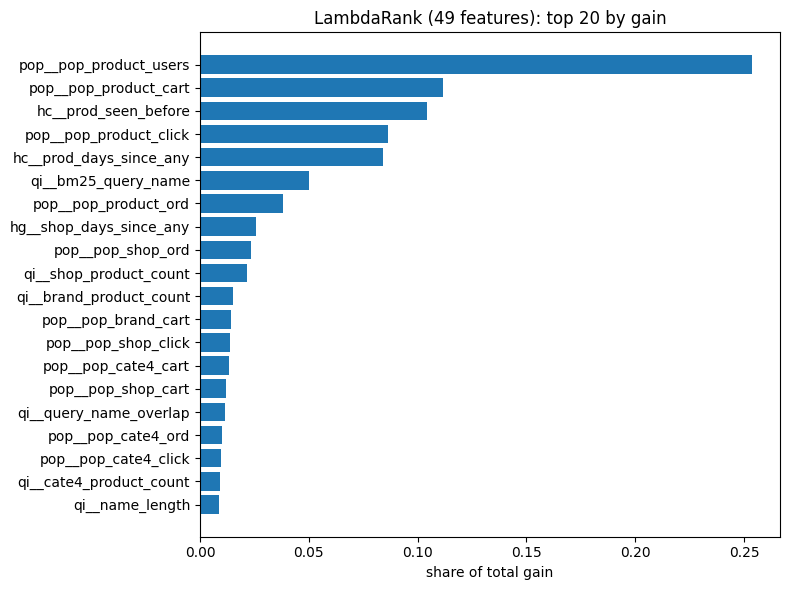

group
popularity    0.603
hist_exact    0.204
query_item    0.131
hist_group    0.062
Name: gain_share, dtype: float64


In [ ]:
imp = pd.DataFrame({'feature': REPORT_FEATS,
                    'gain': REPORT_MODEL.feature_importance('gain', iteration=REPORT_MODEL.best_iteration),
                    'splits': REPORT_MODEL.feature_importance('split', iteration=REPORT_MODEL.best_iteration)})
imp['gain_share'] = imp['gain'] / imp['gain'].sum()
imp['group'] = imp['feature'].str.split('__').str[0].map({'qi': 'query_item', 'hc': 'hist_exact', 'hg': 'hist_group', 'hu': 'hist_user', 'pop': 'popularity'})
imp = imp.sort_values('gain', ascending=False)
imp.to_csv(os.path.join(OUT_DIR, 'feature_importance_lambdarank.csv'), index=False)

top = imp.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top['feature'], top['gain_share'])
ax.set_xlabel('share of total gain'); ax.set_title(f'LambdaRank ({len(REPORT_FEATS)} features): top 20 by gain')
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'feature_importance_top20.png'), dpi=150); plt.show()

print(imp.groupby('group')['gain_share'].sum().sort_values(ascending=False).round(3))

## 11. Save results and test predictions

`results_step3a.csv` goes into the shared results table. The test predictions file is the input for step 4 diagnostics (segment errors by history length, cold vs warm products and so on); it keeps the keys so it joins back to any feature file.

In [ ]:
res = pd.DataFrame(results)
res.to_csv(os.path.join(OUT_DIR, 'results_step3a.csv'), index=False)

pred = data['test'][[GROUP_KEY, ITEM_KEY, LABEL]].copy()
pred['score_lambdarank'] = REPORT_SCORES['test']        # model picked on validation in 9b
pred['rank_lambdarank'] = pred.groupby(GROUP_KEY)['score_lambdarank'].rank(ascending=False, method='first').astype(int)
pred['score_lambdarank_no_pop'] = final_scores['test']
pred['score_lambdarank_pop'] = pop_scores['test']
if BM25_COL:
    pred['score_bm25'] = data['test'][BM25_COL].to_numpy()
pred.to_parquet(os.path.join(OUT_DIR, 'test_predictions_lambdarank.parquet'), index=False)

cols = ['model', 'features', 'split', 'ndcg@5', 'ndcg@10', 'mrr', 'purchase_hit@10']
res.query("model != 'popularity_only'")[cols].pivot_table(index=['model', 'features'], columns='split', values='ndcg@10', sort=False)[['train', 'val', 'test']].round(4)

split                                                  train     val    test
model                features                                               
random               -                                0.0806  0.0809  0.0836
bm25_only            qi__bm25_query_name              0.0933  0.0916  0.0893
lambdarank           all                              0.3637  0.2616  0.2592
lambdarank_ablation  query_item                       0.3144  0.1926  0.1876
                     query_item + hist_exact          0.3811  0.2641  0.2622
                     query_item + hist_exact + group  0.3702  0.2709  0.2681
                     history only                     0.2318  0.2197  0.2187
                     all (adds hist_user)             0.3637  0.2616  0.2592
                     query_item + type-blind history  0.3163  0.2653  0.2623
                     popularity only                  0.3669  0.3426  0.3415
lambdarank_tuned     all                              0.4032  0.2657  0.2615
lambdarank_36f       tuned trees                      0.4220  0.2716  0.2688
                     regularised                      0.3591  0.2741  0.2692
lambdarank_final     36 features (no hist_user)       0.3805  0.2800  0.2744
lambdarank_36f_pop   tuned trees                      0.4574  0.4032  0.4049
                     regularised                      0.4446  0.4059  0.4067
lambdarank_final_pop 49 features (36 + popularity)    0.4435  0.4072  0.4059

In [ ]:
# best single popularity features (no model)
res.query("model == 'popularity_only'").pivot_table(index='features', columns='split', values='ndcg@10')[['train', 'val', 'test']].sort_values('val', ascending=False).round(4)

split,train,val,test
features,,,
pop__pop_product_users,0.3311,0.3277,0.3292
pop__pop_product_cart,0.3200,0.3150,0.3169
pop__pop_product_click,0.3026,0.3008,0.2990
pop__pop_product_ord,0.2734,0.2679,0.2696
pop__pop_shop_cart,0.1914,0.1891,0.1879
pop__pop_shop_ord,0.1921,0.1886,0.1877
pop__pop_shop_click,0.1887,0.1882,0.1850
pop__pop_brand_ord,0.1100,0.1031,0.1049
pop__pop_brand_cart,0.1072,0.0994,0.1019


## 12. Summary of results

- **Final model: 49 features (36 + 13 popularity), regularised.** Test NDCG@10 0.406, about 4.5× BM25 (0.089) and random (0.084); test MRR 0.410, purchase hit@10 0.638.
- **Popularity is the strongest signal:** the best single popularity feature (pop_product_users) reaches 0.329, and LambdaRank on the 13 popularity features alone reaches 0.342, above every model without popularity (0.274).
- **Personal history still adds on top:** adding the 36 query, product and history features to popularity raises test NDCG@10 from 0.342 to 0.406.
- **History matters most without popularity:** query and product features alone reach 0.188; exact-product history raises this to 0.262, and brand, shop and category history to 0.268.
- **User features hurt:** adding them lowers test NDCG@10 from 0.268 to 0.259, so they are dropped.
- **Window ablation:** separating clicks, carts and orders adds only 0.006 over a type-blind history (0.268 vs 0.262).
- **Overfitting:** at learning rate 0.1, stronger regularisation cuts the 36-feature train–test gap from 0.153 to 0.090 with the same test NDCG@10 (0.269). The gap comes mainly from catalogue counts acting as brand and shop IDs. With popularity the final gap is 0.037 (0.443 vs 0.406), because popularity carries over to new searches.
- **Top features (final model):** pop_product_users (25.4%), pop_product_cart (11.2%), prod_seen_before (10.4%). By group: popularity 60%, exact-product history 20%, query and product 13%, brand, shop and category history 6%.
- **No searches excluded:** every search has at least one engaged product.